# ReSnap — Implementasi 3 Materi Pengolahan Citra

Notebook ini memperagakan tiga materi kelas yang dipakai di pipeline ReSnap, memakai fungsi yang sama dengan aplikasi (`src/preprocessing.py`):

| Materi | Teknik di ReSnap | Fungsi |
|---|---|---|
| 1. Histogram | Histogram equalization adaptif (CLAHE) pada kanal L ruang warna LAB | `apply_clahe` |
| 2. Smoothing | Gaussian Blur 5×5 lalu Median Blur 3×3 | `reduce_noise` |
| 3. Segmentasi & Morfologi | Otsu thresholding, opening/closing, `findContours` | `otsu_segment`, `clean_mask`, `find_candidate_contours` |

Setiap bagian berisi gambar sebelum-sesudah, histogram atau ukuran kuantitatif, dan alasan pemilihan parameter. Bagian terakhir menghubungkan ketiganya ke deteksi YOLOv8 dan hasil ablasi pada val/test set.

Foto contoh dari Wikimedia Commons (lisensi CC BY-SA), kreditnya di `contoh/KREDIT_FOTO.md`.

In [1]:
import os, sys
if not os.path.exists('resnap_pipeline.py'):   # notebook dibuka dari folder notebooks/
    os.chdir('..')
sys.path.insert(0, os.getcwd())

import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 72

from src.preprocessing import (resize_keep_ratio, reduce_noise, apply_clahe, otsu_segment,
                               clean_mask, find_candidate_contours, draw_contours, run_pipeline)

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img

def tampil(gambar, judul, kolom=None, ukuran=4):
    kolom = kolom or len(gambar)
    baris = int(np.ceil(len(gambar) / kolom))
    fig, axes = plt.subplots(baris, kolom, figsize=(ukuran * kolom, ukuran * 0.8 * baris))
    for ax, img, j in zip(np.atleast_1d(axes).flat, gambar, judul):
        ax.imshow(rgb(img), cmap='gray' if img.ndim == 2 else None, vmin=0, vmax=255)
        ax.set_title(j, fontsize=10); ax.axis('off')
    for ax in list(np.atleast_1d(axes).flat)[len(gambar):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()

def baca(path):
    img = cv2.imread(path)
    assert img is not None, path
    return resize_keep_ratio(img, interpolation=cv2.INTER_AREA)[0]   # sisi terpanjang 640 px

foto_piring = baca('contoh/udang_piring.jpg')
foto_gelap_latar = baca('contoh/udang_piring_gelap.jpg')
print(foto_piring.shape, foto_gelap_latar.shape)

(480, 640, 3) (640, 480, 3)


## Materi 1 — Histogram: CLAHE pada kanal L

Foto bahan di dapur sering redup atau pencahayaannya tidak rata. Histogram equalization meratakan sebaran intensitas supaya kontras naik. Ada dua pilihan:

- **Global** (`cv2.equalizeHist`): satu fungsi transformasi untuk seluruh gambar. Kontras naik, tapi noise dan area yang sudah terang ikut dikuatkan berlebihan.
- **CLAHE**: equalization per petak 8×8 dengan batas penguatan (`clipLimit`), sehingga lebih halus dan tidak memunculkan artefak.

Equalization hanya diterapkan ke kanal **L** (lightness) di ruang warna LAB. Kalau diterapkan langsung ke R, G, B, warna bahan ikut bergeser, misalnya tomat jadi oranye.

Untuk memperagakan kondisi dapur redup, foto dibuat gelap secara sintetis dengan koreksi gamma (γ = 2.2) dan diperkecil intensitasnya 40%.

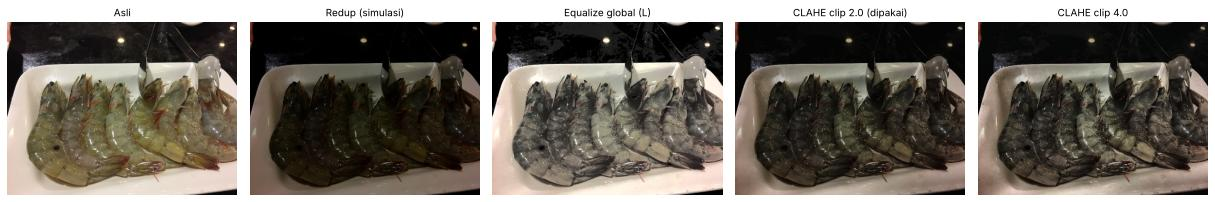

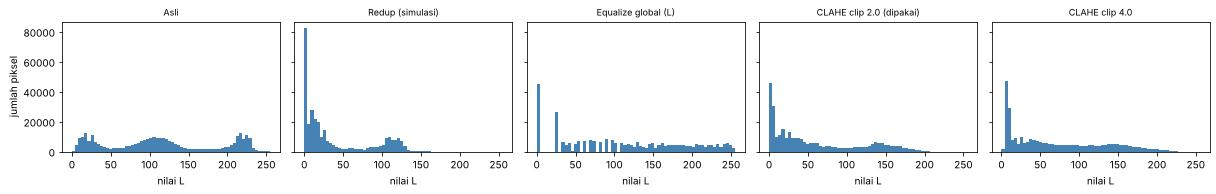

,rata-rata L,std L (kontras),entropi (bit),penguatan noise (x)
versi,,,,
Asli,115.72,71.98,7.58,-
Redup (simulasi),38.23,44.71,5.95,-
Equalize global (L),111.39,80.07,5.95,4.79
CLAHE clip 2.0 (dipakai),58.57,57.01,6.63,2.26
CLAHE clip 4.0,70.89,61.05,6.89,3.41
CLAHE clip 1.0,50.75,53.26,6.29,1.61


In [2]:
def gelapkan(img, gamma=2.2, faktor=0.6):
    x = (img.astype(np.float32) / 255.0) ** gamma * faktor
    return np.clip(x * 255, 0, 255).astype(np.uint8)

def equalize_global_L(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    lab[:, :, 0] = cv2.equalizeHist(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

def kanal_L(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[:, :, 0]

def entropi(ch):
    p = np.bincount(ch.ravel(), minlength=256) / ch.size
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

redup = gelapkan(foto_piring)
varian = {
    'Asli': foto_piring,
    'Redup (simulasi)': redup,
    'Equalize global (L)': equalize_global_L(redup),
    'CLAHE clip 2.0 (dipakai)': apply_clahe(redup, clip_limit=2.0),
    'CLAHE clip 4.0': apply_clahe(redup, clip_limit=4.0),
}
tampil(list(varian.values()), list(varian.keys()), kolom=5, ukuran=3.4)

fig, axes = plt.subplots(1, 5, figsize=(17, 2.8), sharey=True)
for ax, (nama, img) in zip(axes, varian.items()):
    ax.hist(kanal_L(img).ravel(), bins=64, range=(0, 255), color='steelblue')
    ax.set_title(nama, fontsize=9); ax.set_xlabel('nilai L')
axes[0].set_ylabel('jumlah piksel')
plt.tight_layout(); plt.show()

# Penguatan noise: foto redup diberi noise kecil (std 4), lalu diukur seberapa besar noise itu dikuatkan
redup_noise = np.clip(redup.astype(np.float32) + np.random.default_rng(0).normal(0, 4, redup.shape), 0, 255).astype(np.uint8)
metode = {'Equalize global (L)': equalize_global_L,
          'CLAHE clip 1.0': lambda i: apply_clahe(i, clip_limit=1.0),
          'CLAHE clip 2.0 (dipakai)': lambda i: apply_clahe(i, clip_limit=2.0),
          'CLAHE clip 4.0': lambda i: apply_clahe(i, clip_limit=4.0)}
Lf = lambda i: kanal_L(i).astype(np.float32)
noise_awal = (Lf(redup_noise) - Lf(redup)).std()
penguatan = {n: (Lf(f(redup_noise)) - Lf(f(redup))).std() / noise_awal for n, f in metode.items()}

tabel_hist = pd.DataFrame([{'versi': n, 'rata-rata L': kanal_L(i).mean(), 'std L (kontras)': kanal_L(i).std(),
                            'entropi (bit)': entropi(kanal_L(i)), 'penguatan noise (x)': penguatan.get(n, np.nan)}
                           for n, i in list(varian.items()) + [('CLAHE clip 1.0', apply_clahe(redup, clip_limit=1.0))]]
                          ).set_index('versi')
display(tabel_hist.style.format(precision=2, na_rep='-'))

**Membaca hasil:**
- Foto redup punya histogram yang menumpuk di nilai L rendah, dengan kontras (std) dan entropi kecil.
- Equalize global meregangkan histogram ke seluruh rentang 0–255 sehingga kontrasnya bahkan melebihi foto asli. Tetapi entropinya tidak naik, karena nilai yang ada hanya dipindah, bukan ditambah detailnya. Noise juga ikut dikuatkan hampir 5x.
- CLAHE menaikkan kontras **dan** entropi (detail lokal muncul) dengan penguatan noise jauh lebih kecil.
- Makin besar `clipLimit`, makin tinggi kontras tetapi noise juga makin dikuatkan. `clipLimit=2.0` dipilih sebagai titik tengah: kontras naik jauh dari foto redup, sedangkan penguatan noise tetap sekitar separuh dari equalize global.

## Materi 2 — Smoothing: Gaussian + Median

Kamera HP menghasilkan dua jenis noise utama:
- **noise Gaussian** (bintik halus merata akibat sensor), paling cocok diredam filter **Gaussian**;
- **noise impuls / salt-and-pepper** (piksel hitam-putih acak), paling cocok diredam filter **Median**, karena median tidak terpengaruh nilai ekstrem.

Untuk mengukur, foto bersih diberi kedua jenis noise secara sintetis, lalu setiap filter dibandingkan dengan foto bersihnya memakai **PSNR** (semakin tinggi semakin mirip aslinya). Ketajaman tepi diukur dengan **variansi Laplacian**: smoothing yang berlebihan membuatnya turun jauh.

,PSNR (dB),ketajaman (var Laplacian)
filter,,
Tanpa filter,20.1,11368.8
Gaussian 3x3,26.4,314.1
Gaussian 5x5,26.7,85.6
Gaussian 7x7,26.2,25.2
Median 3x3,27.6,350.5
Median 5x5,26.7,147.8
Gaussian 5x5 + Median 3x3 (dipakai),26.8,67.8
Foto bersih (acuan),nan,1325.9


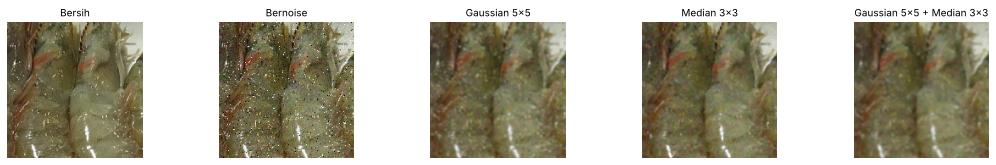

In [3]:
rng = np.random.default_rng(42)
bersih = foto_piring.copy()
noisy = np.clip(bersih.astype(np.float32) + rng.normal(0, 15, bersih.shape), 0, 255).astype(np.uint8)
sp = rng.random(bersih.shape[:2])
noisy[sp < 0.01] = 0
noisy[sp > 0.99] = 255

def ketajaman(img):
    return float(cv2.Laplacian(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var())

filter_uji = {
    'Tanpa filter': noisy,
    'Gaussian 3x3': cv2.GaussianBlur(noisy, (3, 3), 0),
    'Gaussian 5x5': cv2.GaussianBlur(noisy, (5, 5), 0),
    'Gaussian 7x7': cv2.GaussianBlur(noisy, (7, 7), 0),
    'Median 3x3': cv2.medianBlur(noisy, 3),
    'Median 5x5': cv2.medianBlur(noisy, 5),
    'Gaussian 5x5 + Median 3x3 (dipakai)': reduce_noise(noisy, gaussian_ksize=5, median_ksize=3),
}
tabel_smooth = pd.DataFrame([{'filter': n, 'PSNR (dB)': cv2.PSNR(bersih, img), 'ketajaman (var Laplacian)': ketajaman(img)}
                             for n, img in filter_uji.items()]).set_index('filter')
tabel_smooth.loc['Foto bersih (acuan)'] = [np.nan, ketajaman(bersih)]
display(tabel_smooth.style.format(precision=1))

y0, x0 = 180, 200   # potongan 160x160 agar noise terlihat
potong = lambda im: im[y0:y0 + 160, x0:x0 + 160]
tampil([potong(bersih)] + [potong(filter_uji[k]) for k in ('Tanpa filter', 'Gaussian 5x5', 'Median 3x3',
                                                         'Gaussian 5x5 + Median 3x3 (dipakai)')],
       ['Bersih', 'Bernoise', 'Gaussian 5x5', 'Median 3x3', 'Gaussian 5x5 + Median 3x3'], kolom=5, ukuran=3)

**Membaca hasil:**
- Semua filter menaikkan PSNR dari foto bernoise. Variansi Laplacian foto bernoise sangat tinggi karena noise sendiri berupa "tepi" palsu, jadi ukuran ketajaman dibandingkan dengan foto bersih sebagai acuan.
- Untuk campuran noise ini, **Median 3×3 saja** memberi PSNR tertinggi dan mempertahankan detail paling banyak. Median efektif terhadap salt-and-pepper sekaligus cukup meredam noise Gaussian ringan.
- Kombinasi Gaussian 5×5 + Median 3×3 yang dipakai pipeline menghasilkan gambar paling halus (ketajaman terendah). Jadi kombinasi ini **bukan** pilihan terbaik bila tujuannya menjaga detail.

Lalu kenapa pipeline tetap memakai kombinasi itu? Di ReSnap, smoothing dipakai sebelum **segmentasi**, dan yang dibutuhkan di sana adalah tekstur halus (sisik, pantulan, serat talenan) tidak ikut menjadi bintik-bintik di mask Otsu. Sel berikut mengukurnya langsung.

In [4]:
# Smoothing sebagai persiapan segmentasi: jumlah komponen (bintik) pada mask Otsu
baris = []
for path in ('contoh/udang_piring_gelap.jpg', 'contoh/udang_piring.jpg', 'contoh/foto_udang.jpg'):
    img = baca(path)
    for nama, sm in (('tanpa smoothing', img), ('Median 3x3', cv2.medianBlur(img, 3)),
                     ('Gaussian 5x5 + Median 3x3', reduce_noise(img, 5, 3))):
        for kanal in ('gray', 'saturation'):
            _, m, _ = otsu_segment(apply_clahe(sm), channel=kanal)
            n, _, stats, _ = cv2.connectedComponentsWithStats(m)
            baris.append({'foto': path.split('/')[-1], 'smoothing': nama, 'kanal': kanal, 'komponen': n - 1})
tabel_seg = pd.DataFrame(baris).pivot_table(index=['foto', 'kanal'], columns='smoothing', values='komponen')
display(tabel_seg[['tanpa smoothing', 'Median 3x3', 'Gaussian 5x5 + Median 3x3']])

smoothing                          tanpa smoothing  Median 3x3  \
foto                   kanal                                     
foto_udang.jpg         gray                 1161.0       344.0   
                       saturation           1224.0       475.0   
udang_piring.jpg       gray                  888.0       141.0   
                       saturation           1314.0       387.0   
udang_piring_gelap.jpg gray                  372.0        98.0   
                       saturation            322.0        98.0   

smoothing                          Gaussian 5x5 + Median 3x3  
foto                   kanal                                  
foto_udang.jpg         gray                            150.0  
                       saturation                      262.0  
udang_piring.jpg       gray                             51.0  
                       saturation                      169.0  
udang_piring_gelap.jpg gray                             47.0  
                       saturation                       54.0

**Membaca hasil:** di ketiga foto dan kedua kanal, Gaussian 5×5 + Median 3×3 memangkas jumlah komponen mask sekitar separuh dibanding Median 3×3 saja, dan sekitar 5–17x dibanding tanpa smoothing. Jadi pilihan parameter mengikuti tujuannya: smoothing kuat untuk segmentasi; untuk menampilkan foto ke pengguna atau menjaga detail, Median 3×3 lebih tepat.

## Materi 3 — Segmentasi (Otsu) dan Morfologi

**Otsu** memilih ambang secara otomatis dengan memaksimalkan variansi antar-kelas pada histogram, sehingga tidak perlu menebak nilai ambang. Kanal yang di-threshold sangat menentukan hasil:
- kanal **grayscale** memisahkan objek berdasarkan terang-gelap;
- kanal **saturasi (S) dari HSV** memisahkan objek berdasarkan "kepekatan warna", yang tidak bergantung pada pencahayaan. Ini alasan pipeline mengonversi ke HSV.

Mask hasil Otsu lalu dibersihkan dengan **morfologi**: *opening* (erosi lalu dilasi) membuang bintik kecil, *closing* (dilasi lalu erosi) menutup lubang di dalam objek. Terakhir `findContours` menandai area kandidat bahan.

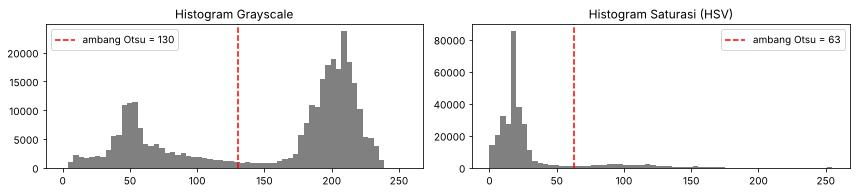

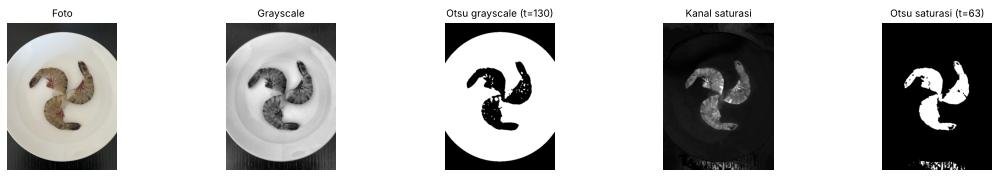

In [5]:
pre = apply_clahe(reduce_noise(foto_gelap_latar))
hsv_s = cv2.cvtColor(pre, cv2.COLOR_BGR2HSV)[:, :, 1]
gray = cv2.cvtColor(pre, cv2.COLOR_BGR2GRAY)
_, mask_gray, t_gray = otsu_segment(pre, channel='gray')
_, mask_sat, t_sat = otsu_segment(pre, channel='saturation')

fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
for ax, ch, t, nama in ((axes[0], gray, t_gray, 'Grayscale'), (axes[1], hsv_s, t_sat, 'Saturasi (HSV)')):
    ax.hist(ch.ravel(), bins=64, range=(0, 255), color='gray')
    ax.axvline(t, color='red', ls='--', label=f'ambang Otsu = {t:.0f}')
    ax.set_title(f'Histogram {nama}'); ax.legend()
plt.tight_layout(); plt.show()

tampil([foto_gelap_latar, gray, mask_gray, hsv_s, mask_sat],
       ['Foto', 'Grayscale', f'Otsu grayscale (t={t_gray:.0f})', 'Kanal saturasi', f'Otsu saturasi (t={t_sat:.0f})'],
       kolom=5, ukuran=3.2)

**Membaca hasil:** Otsu di grayscale justru memilih **piring putih** sebagai objek (piring adalah area paling terang), dan udang menjadi lubang. Di kanal saturasi, piring putih dan meja gelap sama-sama bersaturasi rendah, sedangkan udang lebih berwarna, sehingga Otsu langsung mengisolasi udang. Keterbatasannya: bahan yang memang berwarna pucat (telur, bawang putih, tahu) bersaturasi rendah dan lebih cocok disegmentasi lewat grayscale.

,jumlah komponen,komponen < 200 px (noise),luas foreground (%)
langkah,,,
Otsu saturasi (mentah),54,48,11.30
Opening 3x3,17,14,10.94
Opening 5x5,5,4,10.33
Opening 5x5 + Closing 5x5 (dipakai),5,4,10.52
Opening 9x9 + Closing 9x9,2,0,9.96


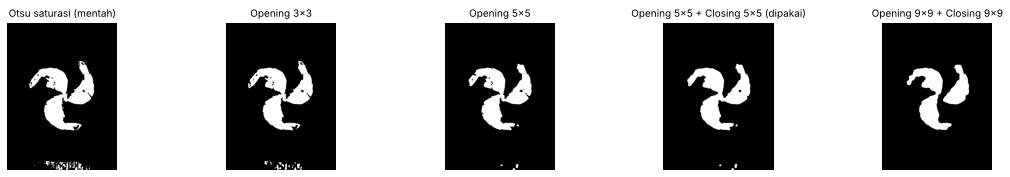

Kontur kandidat bahan: 1 | luas (px): [31327]


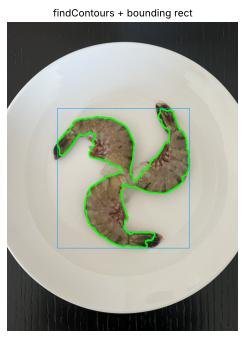

In [6]:
def jumlah_komponen(mask):
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask)
    return n - 1, int((stats[1:, cv2.CC_STAT_AREA] < 200).sum())

k = lambda s: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (s, s))
langkah = {
    'Otsu saturasi (mentah)': mask_sat,
    'Opening 3x3': cv2.morphologyEx(mask_sat, cv2.MORPH_OPEN, k(3), iterations=2),
    'Opening 5x5': cv2.morphologyEx(mask_sat, cv2.MORPH_OPEN, k(5), iterations=2),
    'Opening 5x5 + Closing 5x5 (dipakai)': clean_mask(mask_sat, kernel_size=5, iterations=2),
    'Opening 9x9 + Closing 9x9': clean_mask(mask_sat, kernel_size=9, iterations=2),
}
tabel_morf = pd.DataFrame([{'langkah': n, 'jumlah komponen': jumlah_komponen(m)[0],
                            'komponen < 200 px (noise)': jumlah_komponen(m)[1],
                            'luas foreground (%)': 100 * (m > 0).mean()} for n, m in langkah.items()]).set_index('langkah')
display(tabel_morf.style.format(precision=2))
tampil(list(langkah.values()), list(langkah.keys()), kolom=5, ukuran=3.2)

kontur = find_candidate_contours(langkah['Opening 5x5 + Closing 5x5 (dipakai)'])
print('Kontur kandidat bahan:', len(kontur), '| luas (px):', [int(cv2.contourArea(c)) for c in kontur])
tampil([draw_contours(foto_gelap_latar, kontur)], ['findContours + bounding rect'], ukuran=6)

**Membaca hasil:**
- Mask mentah berisi puluhan komponen, hampir semuanya bintik kecil. *Opening* 5×5 memangkasnya menjadi beberapa komponen saja, dan *closing* menambal lubang di badan udang (luas foreground sedikit naik).
- Beberapa bintik kecil masih tersisa setelah morfologi 5×5. Sisa ini dibuang di tahap berikutnya oleh filter luas di `find_candidate_contours` (kontur di bawah 0,2% luas gambar diabaikan).
- Kernel 9×9 membuang semua bintik, tetapi juga mengikis objek: luas foreground turun sekitar 5%. Karena itu pipeline memakai 5×5 ditambah filter luas, supaya bentuk objek lebih terjaga.

Tiga udang yang saling menempel menjadi **satu kontur**. Segmentasi klasik memisahkan objek dari latar, tetapi tidak bisa memisahkan objek sejenis yang bersentuhan, dan juga tidak tahu jenis bahannya. Karena itu deteksi bahan di ReSnap dilakukan oleh YOLOv8, sementara mask dan kontur dipakai sebagai visualisasi dan analisis area bahan.

## Integrasi ke pipeline ReSnap dan dampaknya ke deteksi

`run_pipeline()` menjalankan ketiga materi berurutan (resize dan HSV, smoothing, CLAHE, Otsu, morfologi dan kontur), lalu menyiapkan input YOLOv8 dengan letterbox 640×640 dan normalisasi piksel ke [0, 1]. Tahapan ini juga ditampilkan di aplikasi Streamlit (expander *Tahapan pra-pemrosesan citra*).

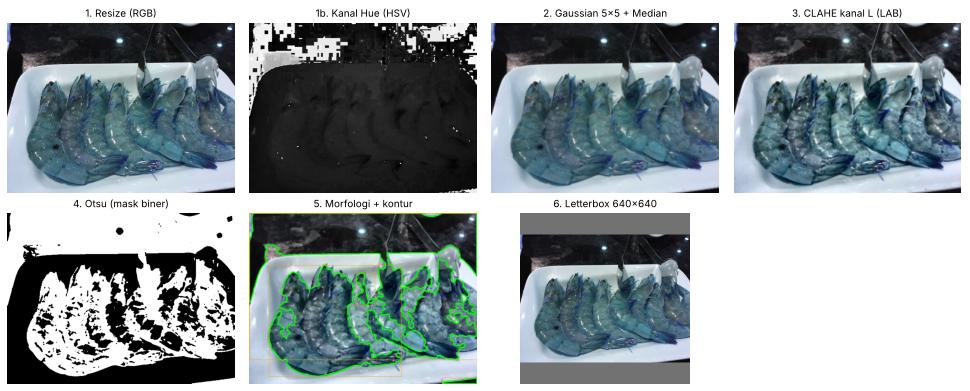

{
 "ukuran_asli": "960x720",
 "ambang_otsu": 125.0,
 "kandidat_kontur": 4,
 "rasio_foreground": 0.553,
 "kecerahan_rata2_L_sebelum": 115.8,
 "kecerahan_rata2_L_sesudah": 122.2,
 "enhance_untuk_deteksi": false
}


Bahan terdeteksi: {'Udang': 8}


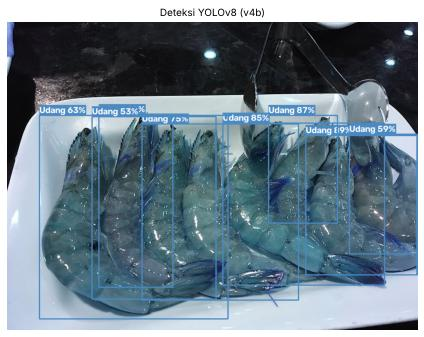

In [7]:
from src.detector import IngredientDetector, draw_detections, display_name

asli = cv2.imread('contoh/udang_piring.jpg')
hasil = run_pipeline(asli)
tahap = hasil.stages()
tampil(list(tahap.values()), list(tahap.keys()), kolom=4, ukuran=3.4)
print(json.dumps(hasil.stats, indent=1))

det = IngredientDetector().detect(hasil, conf=0.5)
print('Bahan terdeteksi:', {display_name(c): v['jumlah'] for c, v in det.ingredients.items()})
tampil([draw_detections(asli, det)], ['Deteksi YOLOv8 (v4b)'], ukuran=6)

### Apakah smoothing + CLAHE membantu YOLO?

Ablasi dijalankan di Kaggle (`ReSnap_Retrain_V4b_Kaggle.ipynb`, `scripts/evaluate_export.py --ablation`): seluruh foto val (1.069) dan test (654) diproses dengan `reduce_noise` + `apply_clahe`, lalu dinilai ulang dengan model yang sama.

In [8]:
abl = {s: json.load(open(f'hasil/ablasi_v4b_{s}.json')) for s in ('val', 'test')}
baris = []
for s in ('val', 'test'):
    for versi, kunci in (('foto mentah', 'raw'), ('smoothing + CLAHE', 'enhanced')):
        m = abl[s][kunci]
        baris.append({'split': s, 'input': versi, 'foto': m['images'], 'precision': m['precision'],
                      'recall': m['recall'], 'mAP50': m['mAP50'], 'mAP50-95': m['mAP50_95']})
display(pd.DataFrame(baris).set_index(['split', 'input']).style.format(precision=3))
print('Selisih (poin persen) val :', abl['val']['delta_pp'])
print('Selisih (poin persen) test:', abl['test']['delta_pp'])

Selisih (poin persen) val : {'precision': -2.29, 'recall': -2.43, 'f1': -2.37, 'mAP50': -3.88, 'mAP50_95': -3.33}
Selisih (poin persen) test: {'precision': -5.21, 'recall': -1.03, 'f1': -3.08, 'mAP50': -5.09, 'mAP50_95': -3.11}


**Kesimpulan:** smoothing + CLAHE **menurunkan** mAP50 sekitar 4–5 poin di val dan test (mAP50-95 sekitar 3 poin). Penjelasan yang paling mungkin: YOLOv8 dilatih dengan foto mentah, sehingga foto yang sudah dihaluskan dan dinaikkan kontrasnya berbeda distribusi dari data latih (*domain shift*), dan detail halus yang dipakai model ikut hilang oleh smoothing. Variasi pencahayaan juga sudah dilatihkan ke model lewat augmentasi HSV saat training.

Karena itu ReSnap memakai ketiga materi untuk tugas yang paling cocok:
- Smoothing, CLAHE, dan segmentasi dipakai untuk **visualisasi dan analisis** (tahapan di aplikasi, area kandidat bahan), serta tersedia sebagai **opsi** untuk foto yang sangat redup (toggle di sidebar).
- Input YOLO secara default hanya melalui **resize + letterbox + normalisasi**, sesuai kondisi saat training.

Temuan ini juga menunjukkan bahwa pra-pemrosesan klasik tidak otomatis memperbaiki model deep learning; pengaruhnya harus diukur, bukan diasumsikan.

## Ringkasan

| Materi | Implementasi | Parameter terpilih | Bukti |
|---|---|---|---|
| Histogram | CLAHE kanal L (LAB) | clipLimit 2.0, petak 8×8 | kontras dan entropi naik; penguatan noise sekitar separuh equalize global |
| Smoothing | Gaussian lalu Median | 5×5 dan 3×3 | bintik mask Otsu berkurang sekitar separuh dibanding Median 3×3 saja; untuk menjaga detail, Median 3×3 saja lebih baik |
| Segmentasi & Morfologi | Otsu (kanal saturasi untuk bahan berwarna), opening + closing, findContours | kernel elips 5×5, 2 iterasi, filter luas 0,2% | komponen turun dari puluhan ke satu kontur; objek bersentuhan tergabung menjadi satu |
| Integrasi | `run_pipeline` → YOLOv8 v4b | input default foto mentah | ablasi val/test: smoothing + CLAHE menurunkan mAP50 sekitar 4–5 poin |